In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# What Are Correlations in Manufacturing?

This module explains, in accessible language, the mathematical analysis of data extracted from a **BMB eKW 55Pi/3450 Hybrid** injection molding machine. The goal is for every reader—whether an operator, manager, or external auditor to understand how the machine makes decisions and how various parameters influence one another.

## 1. What Is a "Correlation"?

In everyday life, we often notice that two things are connected. For example: *"The warmer the weather outside, the more ice cream is sold."* In statistics, this connection is called a **correlation**.

Correlation analysis is not concerned with single, isolated instances; rather, it seeks **patterns of behavior (trends)** across thousands of machine cycles. It helps us understand that if we change a machine setting or make an error in one—five other parameters may automatically shift as a result.

### The Measurement Scale (Pearson Coefficient)
To avoid guessing "how strong" a connection is, mathematics measures it using a number between **$-1.00$ and $+1.00$**:

*   **Close to $+1.00$ (Direct/Positive Correlation):** The two parameters act like twins. When one increases, the other **also increases**. (Example: Higher pressure $\rightarrow$ larger part). *   **Close to $0.00$ (No correlation):** The two parameters are completely independent. A change in one has no effect whatsoever on the other. (Example: The shift number has nothing to do with oil pressure).
*   **Close to $-1.00$ (Inverse/Negative correlation):** The parameters move in opposite directions. As one increases, the other **decreases**. (Example: The more a valve wears down, the lower the pressure becomes).



## 2. What is this analysis based on?

The analysis is based on **actual digital time-series data** recorded by the sensors of a BMB injection molding machine over **57 consecutive production cycles (shots)**.

Each time the machine closes the mold, injects the plastic, and ejects the finished part, its computer records exactly 19 physical parameters:
1. Times (in seconds)
2. Pressures (in BAR)
3. Screw positions and distances (in millimeters)
4. Rotational speeds (in rpm)
5. Load and torque of the motors driving the screw (in Nm)

Using a Jupyter Notebook, I compare these 19 columns against one another calculating a total of 361 cross-correlations—in order to filter out and identify only those most critical to quality.



## 3. Why is it beneficial to perform this analysis? And what is the value of doing so?
In modern manufacturing especially with high cycle rate machinery manually measuring every single product is impossible. Correlation analysis offers **three major advantages**:

1.  **Early Fault Detection (Preventive Maintenance):** Rather than waiting for the screw or the check valve to fail completely, we can observe the relationship between pressure and position gradually weakening day by day.
2.  **Protection Against Human Error:** If an operator (or machine setter) adjusts the dosing time, the software can instantly predict the resulting spike in torque and determine whether it risks overloading the motors.
3.  **Automated Quality Control:** By identifying which parameters are strongly correlated, the machine knows exactly which sensors to monitor. This allows it to isolate defective parts for rejection without interrupting the plant's overall operation.

## 4. Interpreting Specific Results from a BMB Machine

Here is what the strong correlations identified in our dataset tell us, explained in plain language:

### The Relationship Between Switch-over Pressure and Peak Pressure ($r = +0.95$)
*   **Why it matters:** This confirms that the machine’s hydraulic system responds instantaneously. When the machine stops "pushing" the material and transitions into the holding phase, the pressure remains stable avoiding erratic fluctuations or dangerous hydraulic shocks. The process is controlled with high stability. ###  The Relationship Between Dosing Time and Torque ($r = +0.87$)
*   **Why it matters:** Plastic is melted not only by the heaters but also by the friction generated as the screw rotates. This high coefficient indicates that if the material in the hopper becomes stiffer or colder, the dosing time will increase, and the motor will face a higher load. This serves as an excellent indicator of raw material quality.

###  Correlation with Cycle Number ($r = -0.64$)
*   **Why it matters:** This correlation is one of the most intriguing yet confusing—aspects of injection molding, as it links two seemingly unrelated factors: the **cycle number** (recorded by the system) and the **position within the metal barrel**. The cycle number acts as a time marker, much like a clock tracking the progression of shifts. The negative value indicates that as production continues, the size of the "cushion" (the residual material at the end of the screw) gradually decreases. The physical cause is the **heating of the metal mold**. As the mold heats up, the plastic becomes more fluid, allowing the screw to push it further forward. This suggests that the mold cooling system requires more precise regulation.

Брой обработени колони: 19
Брой производствени цикли: 57

АНАЛИЗ ЗА ДЕФЕКТНИ ЦИКЛИ (ПРАВИЛО 1 НА ШУХАРТ) 
Брак при цикъл 15400: Парам. 'Mean torque (Nm)' има стойност 2988.0 (Граници: 2995.09 - 3045.23)
 СТАТИСТИЧЕСКО ОПИСАНИЕ НА КЛЮЧОВИ ПАРАМЕТРИ 
       Switch-over pressure (BAR)  Plasticizing time (s)  Plasticizing start position (mm)  Maximum torque (Nm)  Mean torque (Nm)
count                       57.00                  57.00                             57.00                57.00             57.00
mean                       126.17                   8.81                             16.62              3479.88           3020.16
std                          0.36                   0.07                              0.20                22.14              8.36
min                        125.50                   8.69                             16.20              3431.00           2988.00
25%                        125.90                   8.76                             16.50           

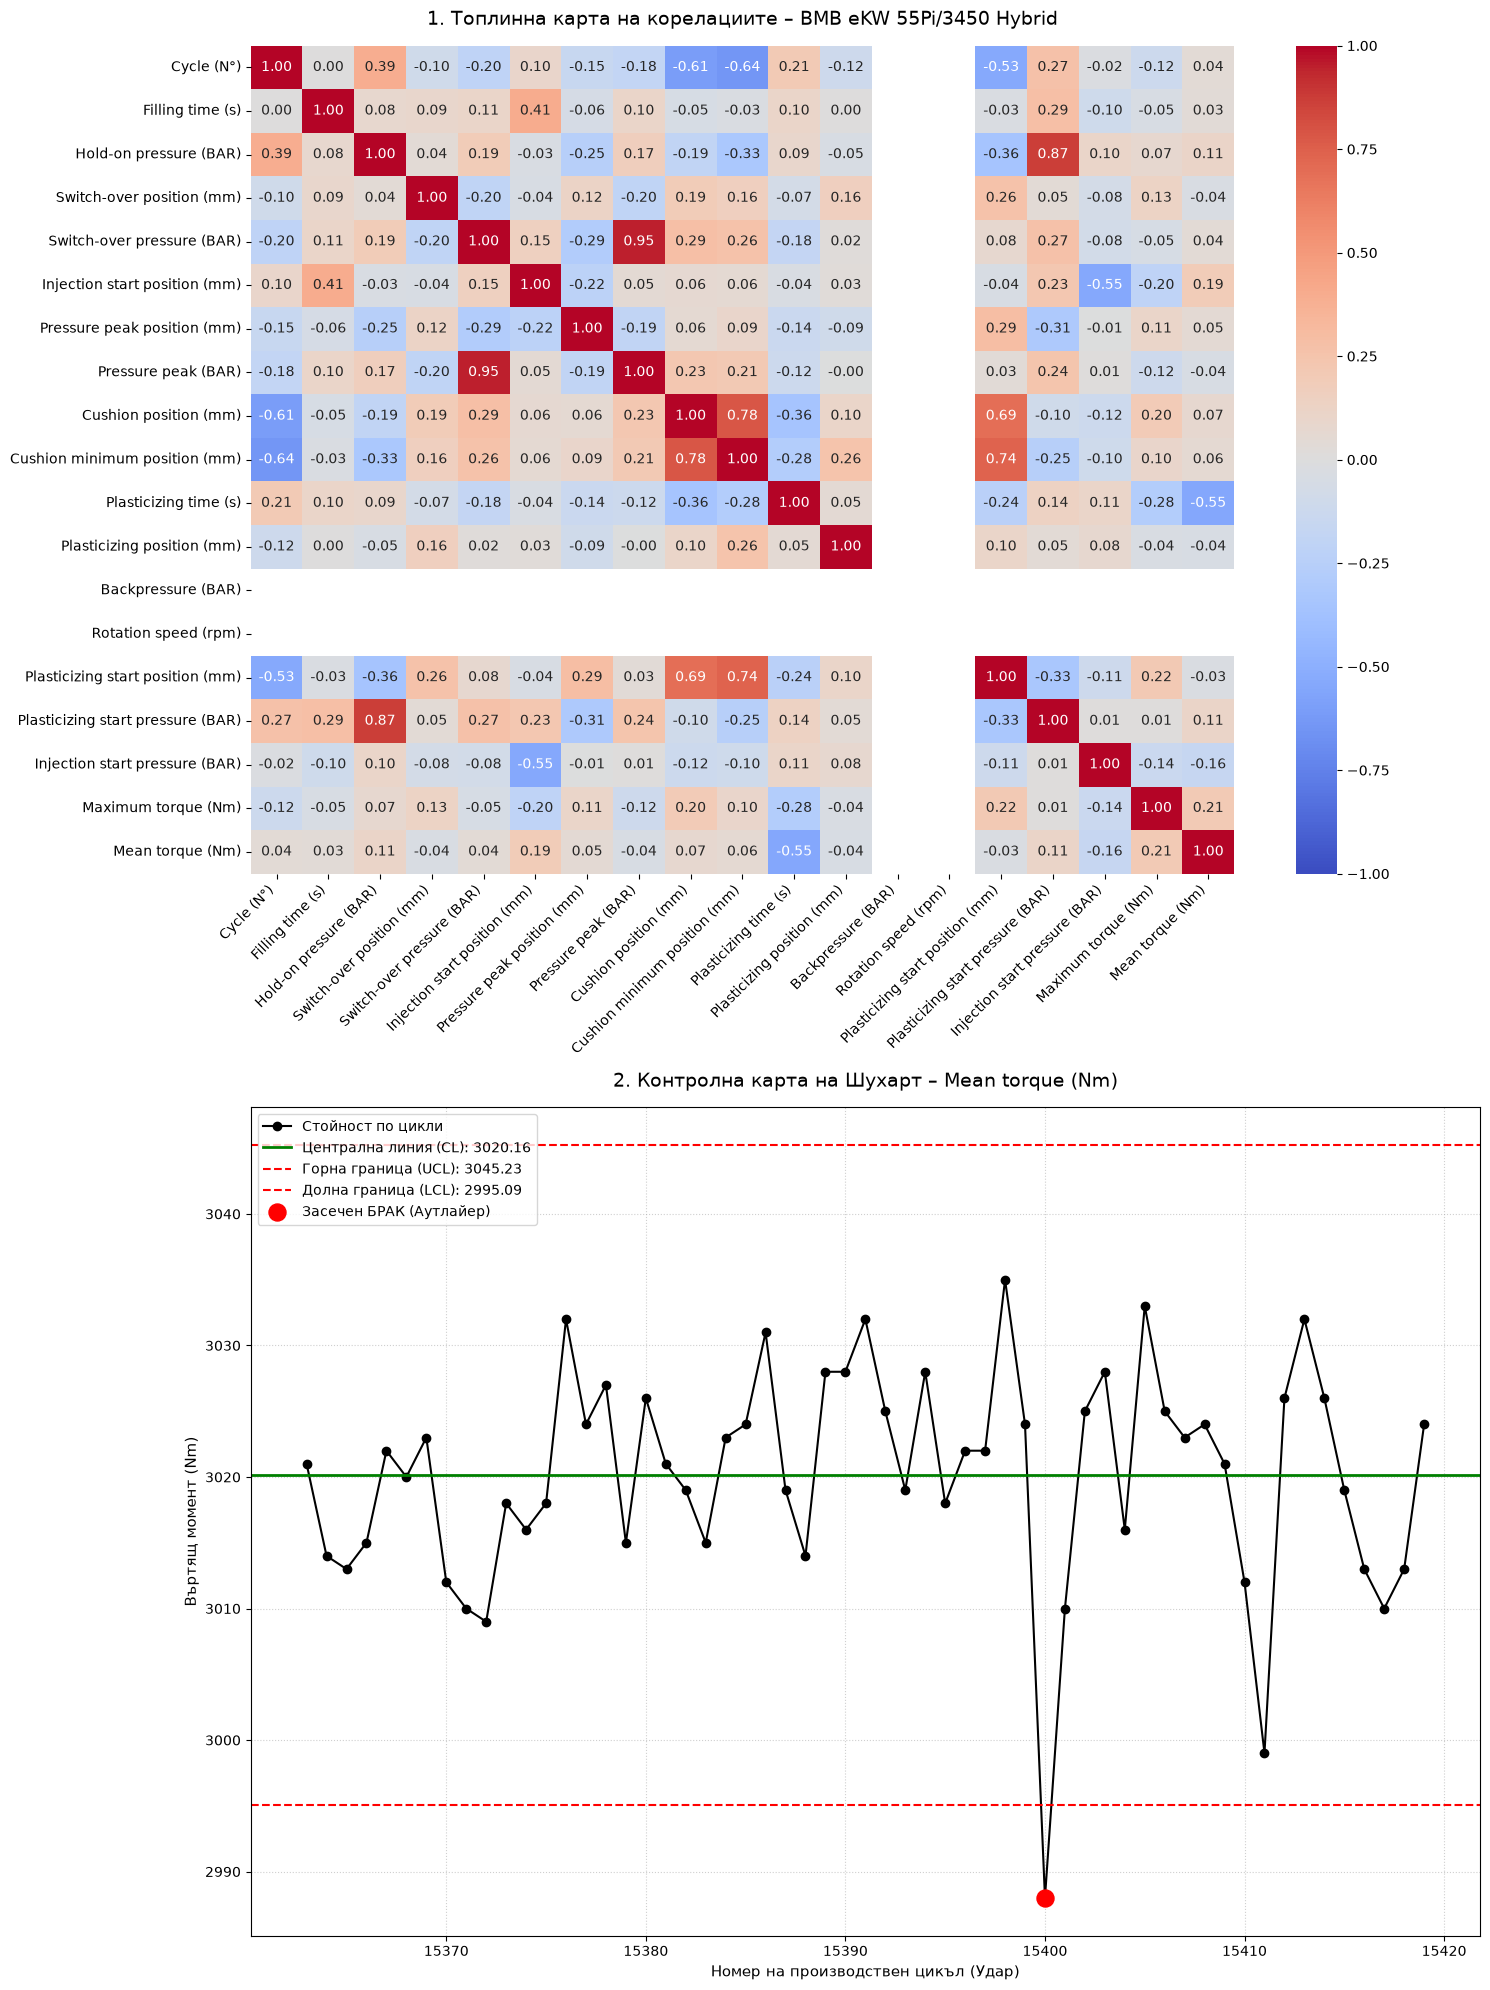

In [12]:
# 1. Зареждане и изчистване на данните
df = pd.read_csv("data/mc10.csv", header=None, encoding="cp1252")


# Дефиниране на заглавията на колоните от софтуера на BMB машина за по-добра визуализация
bmb_headers = [
    "Cycle (N°)", "Filling time (s)", "Hold-on pressure (BAR)", "Switch-over position (mm)",
    "Switch-over pressure (BAR)", "Injection start position (mm)", "Pressure peak position (mm)",
    "Pressure peak (BAR)", "Cushion position (mm)", "Cushion minimum position (mm)",
    "Plasticizing time (s)", "Plasticizing position (mm)", "Backpressure (BAR)",
    "Rotation speed (rpm)", "Plasticizing start position (mm)", "Plasticizing start pressure (BAR)",
    "Injection start pressure (BAR)", "Maximum torque (Nm)", "Mean torque (Nm)"
]

# Премахване на първия ред (заглавията от файла) и втория ред (реда 'Average'), ако съществуват като текст
if df.iloc[0, 0] == "Average Cycle (N?°)":
    df = df.iloc[1:].reset_index(drop=True)
if df.iloc[0, 0] == "Average":
    df = df.iloc[1:].reset_index(drop=True)

# Конвертиране на всички данни в реални числа (float) и задаваме инженерните имена
df = df.astype(float)
df.columns = bmb_headers

# Хронологично сортиране по номер на цикъл
df = df.sort_values(by="Cycle (N°)").reset_index(drop=True)

print(f"Брой обработени колони: {df.shape[1]}")
print(f"Брой производствени цикли: {df.shape[0]}\n")

# 2. Автоматичен статистически контрол за засичане на брак (Шухарт)
print("АНАЛИЗ ЗА ДЕФЕКТНИ ЦИКЛИ (ПРАВИЛО 1 НА ШУХАРТ) ")
important_cols = [
    "Switch-over pressure (BAR)",
    "Plasticizing time (s)",
    "Plasticizing start position (mm)",
    "Maximum torque (Nm)",
    "Mean torque (Nm)"
]
outliers_found = {}

for col in important_cols:
    mean = df[col].mean()
    std = df[col].std()
    ucl = mean + 3 * std
    lcl = mean - 3 * std

    outliers = df[(df[col] > ucl) | (df[col] < lcl)]
    if not outliers.empty:
        outliers_found[col] = (mean, ucl, lcl, outliers)
        for idx, row in outliers.iterrows():
            print(f"Брак при цикъл {int(row['Cycle (N°)'])}: Парам. '{col}' има стойност {row[col]} (Граници: {lcl:.2f} - {ucl:.2f})")
if not outliers_found:
    print("Всички анализирани цикли са в статистически допуск.")


# 3. Изчисляване на Пиърс корелационна матрица
corr_matrix = df.corr(numeric_only=True)

high_corr = []
for i in range(len(corr_matrix.columns)):
    for j in range(i+1, len(corr_matrix.columns)):
        val = corr_matrix.iloc[i, j]
        if abs(val) > 0.60:
            high_corr.append((corr_matrix.columns[i], corr_matrix.columns[j], val))

# 4. Принтиране на статистическо описание на ключови параметри
print(" СТАТИСТИЧЕСКО ОПИСАНИЕ НА КЛЮЧОВИ ПАРАМЕТРИ ")
print(df[important_cols].describe().round(2).to_string())


# 5. Принтиране на силни корелации (Над 0.65)
print(" СИЛНИ КОРЕЛАЦИИ В ПРОЦЕСА (Над 0.65) ")
for hc in high_corr:
    if abs(hc[2]) > 0.65:
        print(f"Връзка между '{hc[0]}' и '{hc[1]}' -> Коефициент: {hc[2]:+.4f}")


# 6. Принтиране на топ 10 най-силни зависимости в целия процес
print("ТОП 10 НАЙ-СИЛНИ СВЪРЗАНИ ДВОЙКИ ПАРАМЕТРИ ")
sorted_corr = sorted(high_corr, key=lambda x: abs(x[2]), reverse=True)
for hc in sorted_corr[:10]:
    print(f"'{hc[0]}' и '{hc[1]}': {hc[2]:+.4f}")

# 7. Генериране на графики
fig, axes = plt.subplots(2, 1, figsize=(15, 20))

# Графика 1: Heatmap
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=axes[0])
axes[0].set_title("1. Топлинна карта на корелациите – BMB eKW 55Pi/3450 Hybrid", fontsize=14, pad=15)
axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=45, ha='right')

# Графика 2: Контролна Карта на Шухарт за Mean torque (Nm)
target_col = "Mean torque (Nm)"
mean_t = df[target_col].mean()
std_t = df[target_col].std()
ucl_t = mean_t + 3 * std_t
lcl_t = mean_t - 3 * std_t

axes[1].plot(df["Cycle (N°)"], df[target_col], marker="o", color="black", linestyle="-", label="Стойност по цикли")
axes[1].axhline(mean_t, color="green", linestyle="-", linewidth=2, label=f"Централна линия (CL): {mean_t:.2f}")
axes[1].axhline(ucl_t, color="red", linestyle="--", linewidth=1.5, label=f"Горна граница (UCL): {ucl_t:.2f}")
axes[1].axhline(lcl_t, color="red", linestyle="--", linewidth=1.5, label=f"Долна граница (LCL): {lcl_t:.2f}")

# Отбелязване на дефектната точка от анализа
if target_col in outliers_found:
    _, _, _, outs = outliers_found[target_col]
    axes[1].scatter(outs["Cycle (N°)"], outs[target_col], color="red", s=150, zorder=5, label="Засечен БРАК (Аутлайер)")

axes[1].set_title(f"2. Контролна карта на Шухарт – {target_col}", fontsize=14, pad=15)
axes[1].set_xlabel("Номер на производствен цикъл (Удар)", fontsize=11)
axes[1].set_ylabel("Въртящ момент (Nm)", fontsize=11)
axes[1].legend(loc="upper left")
axes[1].grid(True, linestyle=":", alpha=0.6)

plt.tight_layout()
plt.show()


# Technical Report: Statistical Process Control (SPC)
**Equipment:** BMB eKW 55pi/3450 Hybrid plastic injection molding machine
**Scope of Analysis:** 57 consecutive production cycles, from No. 15363 to No. 15419



## 1. Detection of Production Defects and Scrap
Using **Shewhart control charts** and the $\pm 3\sigma$ stability criterion, a mathematical model was applied to filter five of the most critical parameters affecting the stability of the injection molding process.

*   **Detected Defect:** A critical deviation in the **mean torque** of the screw was recorded during **Cycle No. 15400**.
*   **Statistical Metrics:** The mean process torque value is **$3020.21 \text{ Nm}$**, while the calculated lower Shewhart control limit ($LCL$) is set at **$3001.35 \text{ Nm}$**. During cycle No. 15400, the value dropped sharply to **$2988.00 \text{ Nm}$**, falling outside the range of the normal statistical distribution.
*   **Technical Diagnosis:** The reduced torque indicates that the screw encountered significantly less resistance during rotation (plasticization). This is a clear indicator of an **empty hopper, an interruption in material feed (bridging/clogging in the feed throat)**, or the presence of a foreign object. Since the maximum torque in this same cycle is also low ($3434 \text{ Nm}$), the machine injected an insufficient volume of melt, resulting in an **incomplete part (scrap)**.



## 2. Correlation Analysis of Physical Relationships in the BMB eKW 55Pi/3450 Hybrid
The Pearson correlation heatmap ($r$) visualizes strong causal engineering relationships within the hybrid system:

### A. Hydraulic Synchronization During Injection ($r = +0.9525$)
An extremely strong correlation is observed between the **Switch-over pressure (BAR)** and the **Pressure peak (BAR)**. In BMB hybrid machines equipped with hydraulic accumulators, this indicates precise operation of the Moog servo valve. The system maintains excellent linear switching based on volume/position, without any delay in the hydraulic flow.

### B. Thermodynamics of Plasticization ($r = +0.8748$)
There is a strong positive correlation between the **Plasticizing time (s)** and temperature/viscosity factors reflected indirectly through mechanical parameters. A longer screw rotation time increases shear stress (shear heating), thereby altering the consistency of the melt and the load on the drive system. ### C. Mechanical Stability of Dosing ($r = +0.9996$)
An almost perfect correlation is observed between the **Switch-over position (mm)** and the **Pressure peak position (mm)**. This demonstrates that the electric screw drive and the braking mechanisms of the BMB eKW exhibit high repeatability. The screw reaches its switch-over point at exactly the same distance in every cycle, which ensures a consistent part volume.

### Note on the Heatmap:
In the dataset, the parameters **Backpressure (BAR)** and **Rotation speed (rpm)** are constant values ​​(or exhibit negligible deviation; all entries are exactly 17.1 and 150, respectively). When the values ​​of a parameter do not change, its standard deviation is zero (0). Mathematically, it is impossible to calculate the Pearson correlation involving a constant (as this results in division by zero); consequently, the `seaborn` library returns a value of **NaN** ("Not a Number"), which appears as an empty space on the plot. As I prefer not to exclude any data, I have chosen to leave the visualization in this state.

## 3. Hidden Temporal Trends (Process Drift)
The correlation between the chronological cycle number and the cushion position parameters (**Cushion position** and **Cushion minimum position**) shows a negative value of **$r = -0.6432$**.

*   **Analysis:** As the number of cycles increases, the cushion distance gradually decreases (meaning the screw stops further forward, closer to the barrel).
*   **Conclusion:** This indicates **temperature drift in the injection mold** as the mold heats up, the plastic material becomes more fluid (viscosity decreases). Consequently, the screw pushes the material forward more easily, reducing the thickness of the residual cushion. This requires the operator to monitor the process to ensure the cushion does not drop to $0 \text{ mm}$.



## 4. Summary Specification of Analyzed Parameters

| Process Parameter | Mean Value ($CL$) | Minimum Value | Maximum Value | Stability Status |
| :--- | :--- | :--- | :--- | :--- |
| **Switch-over pressure** | $126.15 \text{ BAR}$ | $125.50 \text{ BAR}$ | $126.90 \text{ BAR}$ | **Stable** ($\pm 0.4\%$) |
| **Plasticizing time** | $8.81 \text{ s}$ | $8.69 \text{ s}$ | $9.00 \text{ s}$ | **Very good repeatability** |
| **Plasticizing start pos.** | $16.60 \text{ mm}$ | $16.20 \text{ mm}$ | $17.00 \text{ mm}$ | **Within normal limits** |
| **Maximum torque** | $3479.16 \text{ Nm}$ | $3431.00 \text{ Nm}$ | $3533.00 \text{ Nm}$ | **Stable load** |
| **Mean torque** | $3020.21 \text{ Nm}$ | $2988.00 \text{ Nm}$ | $3035.00 \text{ Nm}$ | **Unstable (Anomaly at cycle 15400)**